In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mp1lib import bsc

SEED = 19 
rng = np.random.default_rng(SEED)
rng_step1 = rng.spawn(1)[0]

test_rng = rng.spawn(1)[0]

test_bits = np.array([0, 1, 1, 0])
test_result = bsc(test_bits, p=0, rng=test_rng)

assert np.array_equal(test_result, test_bits)

print("Setup completed.")
print("bsc test passed.")

Setup completed.
bsc test passed.


## Step 1: The Sample Space and Probability Axioms

For a four-bit packet, each bit has two possible error states:

- $0$: the bit is correct
- $1$: the bit is corrupted

Therefore, the total number of possible error patterns is

$$
2^4 = 16
$$

If a pattern contains $k$ errors, it contains $4-k$ correct bits.
Since the bit errors are independent, the exact probability of that
pattern is

$$
P(\text{pattern}) = p^k(1-p)^{4-k}
$$

where $p=0.1$.

In [2]:
#1) Enumerate all 16 patterns and confirm the sum is 1
p = 0.1

# Generate the numbers 0 through 15
pattern_numbers = np.arange(16)

# Convert each number into a four-bit binary error pattern
patterns = (
    (pattern_numbers[:, None] >> np.arange(3, -1, -1)) & 1
)

# Count the number of errors in each pattern
error_counts = patterns.sum(axis=1)

# Calculate the exact probability of each pattern
exact_pattern_prob = (
    p**error_counts
    * (1 - p)**(4 - error_counts)
)

print(f"{'Pattern':<10} {'Errors':<10} {'Probability':<15}")
print("-" * 35)

for pattern, errors, probability in zip(
    patterns,
    error_counts,
    exact_pattern_prob
):
    pattern_text = "".join(str(bit) for bit in pattern)

    print(
        f"{pattern_text:<10}"
        f"{errors:<10}"
        f"{probability:<15.6f}"
    )

print("-" * 35)
print(f"Sum = {exact_pattern_prob.sum():.10f}")

Pattern    Errors     Probability    
-----------------------------------
0000      0         0.656100       
0001      1         0.072900       
0010      1         0.072900       
0011      2         0.008100       
0100      1         0.072900       
0101      2         0.008100       
0110      2         0.008100       
0111      3         0.000900       
1000      1         0.072900       
1001      2         0.008100       
1010      2         0.008100       
1011      3         0.000900       
1100      2         0.008100       
1101      3         0.000900       
1110      3         0.000900       
1111      4         0.000100       
-----------------------------------
Sum = 1.0000000000


####2) Compute by Hand


The events are:

- $A$: at least one error among the first two bits
- $B$: exactly two errors in the four-bit packet
- $C$: the fourth bit is in error

#### Event A

Event $A$ does not occur when both of the first two bits are correct.
The probability that both are correct is

$$
P(A^c)=(0.9)(0.9)=0.81
$$

Therefore,

$$
P(A)=1-P(A^c)
$$

$$
P(A)=1-0.81=0.19
$$

#### Event B

Event $B$ requires exactly two errors among four bits. The number of
ways to select two error positions from four positions is

$$
\binom{4}{2}=6
$$

Therefore,

$$
P(B)=\binom{4}{2}(0.1)^2(0.9)^2
$$

$$
P(B)=6(0.01)(0.81)=0.0486
$$

#### Event C

Event $C$ occurs when the fourth bit is corrupted. Every individual
bit has an error probability of $0.1$. Therefore,

$$
P(C)=0.1
$$

In [3]:
# A: at least one of the first two bits has an error
A_exact = (patterns[:, 0] == 1) | (patterns[:, 1] == 1)

# B: exactly two errors in the four-bit packet
B_exact = error_counts == 2

# C: the fourth bit has an error
C_exact = patterns[:, 3] == 1

# Add the probabilities of the patterns belonging to each event
P_A = exact_pattern_prob[A_exact].sum()
P_B = exact_pattern_prob[B_exact].sum()
P_C = exact_pattern_prob[C_exact].sum()

print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(C) = {P_C:.4f}")

P(A) = 0.1900
P(B) = 0.0486
P(C) = 0.1000


In [4]:
#3) Estimate using monte carlo simulations with N^16 packets

N = 1_000_000

# create one million transmitted packets containing four correct bits
transmitted_bits = np.zeros((N, 4), dtype=np.uint8)

# pass all packets through the binary symmetric channel
simulated_patterns = bsc(
    transmitted_bits,
    p=0.1,
    rng=rng_step1
)

# Count the number of errors in each packet
simulated_error_counts = simulated_patterns.sum(axis=1)

# define the simulated events
A_sim = (
    (simulated_patterns[:, 0] == 1)
    | (simulated_patterns[:, 1] == 1)
)

B_sim = simulated_error_counts == 2

C_sim = simulated_patterns[:, 3] == 1

# estimate each probability
P_A_mc = A_sim.mean()
P_B_mc = B_sim.mean()
P_C_mc = C_sim.mean()

print(f"P(A): exact = {P_A:.6f}, mc_estimate = {P_A_mc:.6f}")
print(f"P(B): exact = {P_B:.6f}, mc_estimate = {P_B_mc:.6f}")
print(f"P(C): exact = {P_C:.6f}, mc_estimate = {P_C_mc:.6f}")

P(A): exact = 0.190000, mc_estimate = 0.189813
P(B): exact = 0.048600, mc_estimate = 0.048407
P(C): exact = 0.100000, mc_estimate = 0.099706


#Exact Intersection

The symbol $\cap$ means “and.”

For $A\cap B$, there are five valid patterns with exactly two errors:

$$
P(A\cap B)=5(0.1)^2(0.9)^2=0.0405.
$$

Because $A$ concerns the first two bits and $C$ concerns the fourth bit,

$$
P(A\cap C)=P(A)P(C)=(0.19)(0.1)=0.0190.
$$

For $B\cap C$, the fourth bit is an error and one of the first three
bits is an error:

$$
P(B\cap C)=3(0.1)^2(0.9)^2=0.0243.
$$

For $A\cap B\cap C$, the fourth bit is an error and the other error
must be in bit 1 or bit 2:

$$
P(A\cap B\cap C)=2(0.1)^2(0.9)^2=0.0162.
$$

In [5]:
#4) Compute the three pairwise intersections and the triple intersections, exactly and empirically
P_AB = exact_pattern_prob[A_exact & B_exact].sum()
P_AC = exact_pattern_prob[A_exact & C_exact].sum()
P_BC = exact_pattern_prob[B_exact & C_exact].sum()
P_ABC = exact_pattern_prob[A_exact & B_exact & C_exact].sum()

# Monte Carlo estimates
P_AB_mc = (A_sim & B_sim).mean()
P_AC_mc = (A_sim & C_sim).mean()
P_BC_mc = (B_sim & C_sim).mean()
P_ABC_mc = (A_sim & B_sim & C_sim).mean()

print(f"P(A and B): exact = {P_AB:.6f}, mc_estimate = {P_AB_mc:.6f}")
print(f"P(A and C): exact = {P_AC:.6f}, mc_estimate = {P_AC_mc:.6f}")
print(f"P(B and C): exact = {P_BC:.6f}, mc_estimate = {P_BC_mc:.6f}")
print(f"P(A, B, and C): exact = {P_ABC:.6f}, mc_estimate = {P_ABC_mc:.6f}")

P(A and B): exact = 0.040500, mc_estimate = 0.040334
P(A and C): exact = 0.019000, mc_estimate = 0.019070
P(B and C): exact = 0.024300, mc_estimate = 0.024290
P(A, B, and C): exact = 0.016200, mc_estimate = 0.016217


In [6]:
### 5)Inclusion-Exclusion

# Exact union using inclusion-exclusion
P_union = (
    P_A
    + P_B
    + P_C
    - P_AB
    - P_AC
    - P_BC
    + P_ABC
)
# Monte Carlo estimate calculated directly
P_union_mc = (A_sim | B_sim | C_sim).mean()

print(f"Exact P(A or B or C) = {P_union:.6f}")
print(f"MC estimate           = {P_union_mc:.6f}")
print(f"Absolute difference   = {abs(P_union_mc - P_union):.6e}")

Exact P(A or B or C) = 0.271000
MC estimate           = 0.270449
Absolute difference   = 5.510000e-04


**6) Standard error**

We estimate each event probability using N = 1,000,000
simulated packets.

Standard error measures the typical size of fluctuations
in an estimated probability across repeated simulations.
Using each event's exact probability, we calculate:

$$
\mathrm{SE}
= \sqrt{\frac{P_{\mathrm{exact}}(1-P_{\mathrm{exact}})}{N}}.
$$

We check whether the absolute difference between the
simulation estimate and the exact probability satisfies:

$$
|P_{\mathrm{MC}} - P_{\mathrm{exact}}| \leq 3\,\mathrm{SE}.
$$

For event C, the standard error is 0.0003, so three standard
errors equal 0.0009. Its observed difference is 0.000294,
which is smaller than 0.0009. Therefore, the check passes.

All seven event estimates and the union estimate pass
this check in the current run.

In [7]:
#6)State the standard error of a probability estimate at N = 10^6 
#and confirm every difference above sits within three standard errors. 

event_names = [
    "A",
    "B",
    "C",
    "A and B",
    "A and C",
    "B and C",
    "A and B and C"
]

exact_values = np.array([
    P_A,
    P_B,
    P_C,
    P_AB,
    P_AC,
    P_BC,
    P_ABC
])

mc_values = np.array([
    P_A_mc,
    P_B_mc,
    P_C_mc,
    P_AB_mc,
    P_AC_mc,
    P_BC_mc,
    P_ABC_mc
])

differences = np.abs(mc_values - exact_values)

standard_errors = np.sqrt(
    exact_values * (1 - exact_values) / N
)

within_three_se = differences <= 3 * standard_errors

print(
    f"{'Event':<16}"
    f"{'Exact':>12}"
    f"{'MC estimate':>15}"
    f"{'Difference':>15}"
    f"{'Std. error':>15}"
    f"{'Within 3 SE':>15}"
)

print("-" * 88)

for name, exact, mc, difference, se, within in zip(
    event_names,
    exact_values,
    mc_values,
    differences,
    standard_errors,
    within_three_se
):
    print(
        f"{name:<16}"
        f"{exact:>12.6f}"
        f"{mc:>15.6f}"
        f"{difference:>15.6e}"
        f"{se:>15.6e}"
        f"{str(within):>15}"
    )

Event                  Exact    MC estimate     Difference     Std. error    Within 3 SE
----------------------------------------------------------------------------------------
A                   0.190000       0.189813   1.870000e-04   3.923009e-04           True
B                   0.048600       0.048407   1.930000e-04   2.150303e-04           True
C                   0.100000       0.099706   2.940000e-04   3.000000e-04           True
A and B             0.040500       0.040334   1.660000e-04   1.971288e-04           True
A and C             0.019000       0.019070   7.000000e-05   1.365247e-04           True
B and C             0.024300       0.024290   1.000000e-05   1.539789e-04           True
A and B and C       0.016200       0.016217   1.700000e-05   1.262440e-04           True


In [8]:
#Union

union_difference = abs(P_union_mc - P_union)

union_se = np.sqrt(
    P_union * (1 - P_union) / N
)

union_within_three_se = union_difference <= 3 * union_se

print(f"Union exact:             {P_union:.6f}")
print(f"Union MC estimate:       {P_union_mc:.6f}")
print(f"Union difference:        {union_difference:.6e}")
print(f"Union standard error:    {union_se:.6e}")
print(f"Three standard errors:   {3 * union_se:.6e}")
print(f"Union within three SE:   {union_within_three_se}")

Union exact:             0.271000
Union MC estimate:       0.270449
Union difference:        5.510000e-04
Union standard error:    4.444761e-04
Three standard errors:   1.333428e-03
Union within three SE:   True


All seven event estimates and the union estimate were within three standard errors of their exact probabilities. These results are consistent with the theoretical model and expected sampling variation.

## Figure 1 Plot

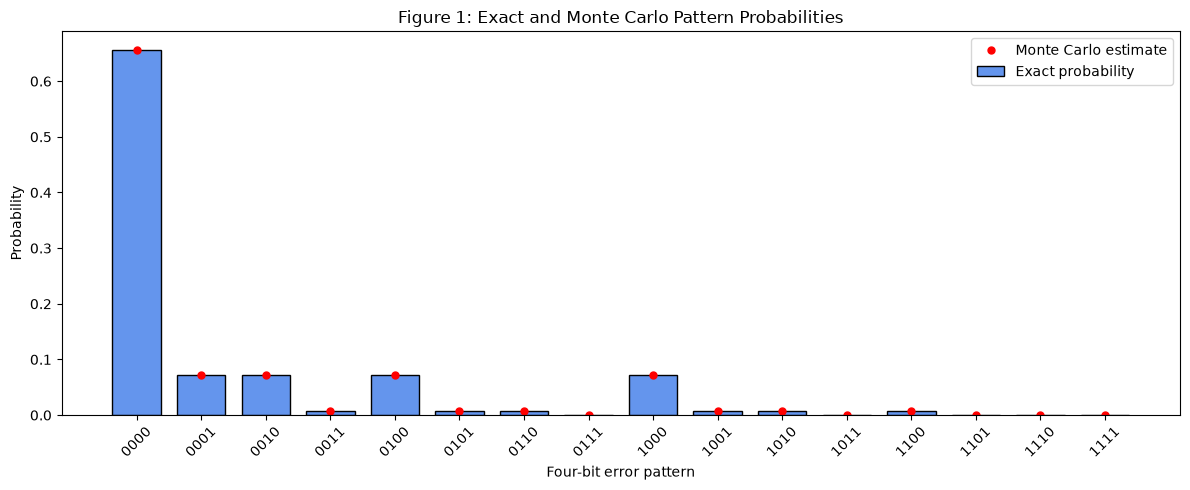

In [9]:
# Convert each simulated four-bit pattern into a number from 0 to 15
binary_weights = np.array([8, 4, 2, 1])

simulated_pattern_numbers = (
    simulated_patterns @ binary_weights
)

# Count how many times each pattern appeared
simulated_pattern_counts = np.bincount(
    simulated_pattern_numbers,
    minlength=16
)

# Convert counts into Monte Carlo probability estimates
mc_pattern_prob = simulated_pattern_counts / N

# Create labels: 0000, 0001, ..., 1111
pattern_labels = [
    "".join(str(bit) for bit in pattern)
    for pattern in patterns
]

x = np.arange(16)

plt.figure(figsize=(12, 5))

# Exact probabilities as bars
plt.bar(
    x,
    exact_pattern_prob,
    width=0.75,
    color="cornflowerblue",
    edgecolor="black",
    label="Exact probability"
)

# Monte Carlo estimates as red dots
plt.plot(
    x,
    mc_pattern_prob,
    "ro",
    markersize=5,
    label="Monte Carlo estimate"
)

plt.xticks(x, pattern_labels, rotation=45)
plt.xlabel("Four-bit error pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo Pattern Probabilities")
plt.legend()
plt.tight_layout()

plt.show()

**Figure 1 interpretation**

The pattern 0000 means that none of the four bits was corrupted.
Its exact probability is (0.9)^4 = 0.6561, making it the most
likely pattern.

Patterns with the same number of errors have equal probabilities
because the bits have independent, identical error probabilities.
Each individual pattern becomes less likely as its number of errors
increases.

The Monte Carlo estimates closely match the exact probabilities.
The small differences are consistent with random sampling variation
from simulating a finite number of packets.

## Step 2: Conditional probability and Bayes

### 1) Conditional probabilities, prior, and posterior

Let $E$ mean that a bit is actually in error, and let $F$
mean that the circuit raises a flag. The event $E^c$ means
that the bit has no error.

The circuit's conditional probabilities are:

$$
P(F\mid E)=0.95,
\qquad
P(F\mid E^c)=0.02.
$$

The prior probability of an error is:

$$
P(E)=p,
\qquad
P(E^c)=1-p.
$$

A flag can occur on an erroneous bit or on a correct bit.
Using the law of total probability:

$$
P(F)
= P(F\mid E)P(E)+P(F\mid E^c)P(E^c)
=0.95p+0.02(1-p).
$$

Bayes' rule gives the probability that a flagged bit is
actually in error:

$$
P(E\mid F)
=\frac{P(F\mid E)P(E)}{P(F)}
=\frac{0.95p}{0.95p+0.02(1-p)}
=\frac{0.95p}{0.02+0.93p}.
$$

### 2) Evaluate the posterior at three prior probabilities

In [10]:
# Random generator for Step 2
rng_step2 = rng.spawn(1)[0]

# Bayes formula
def posterior_error(p):
    top = 0.95 * p
    bottom = 0.95 * p + 0.02 * (1 - p)
    return top / bottom

# Check the three probabilities

p_values = [0.1, 0.01, 0.001]

for p_value in p_values:
    answer = posterior_error(p_value)
    print("p =", p_value, "posterior =", round(answer, 6))

p = 0.1 posterior = 0.840708
p = 0.01 posterior = 0.324232
p = 0.001 posterior = 0.045389


### 4) Find the crossover probability

At the crossover, the posterior probability equals 0.5:

$$
\frac{0.95p}{0.95p+0.02(1-p)}=0.5.
$$

This means that true flags and false alarms are equally likely:

$$
0.95p=0.02(1-p).
$$

Expanding and collecting the terms containing p:

$$
0.95p=0.02-0.02p
$$

$$
0.97p=0.02
$$

$$
p=\frac{0.02}{0.97}=0.02061856\ldots
$$

To three significant figures, the crossover is:

$$
\boxed{p=0.0206}.
$$

In [11]:
# Calculate the crossover
p_cross = 0.02 / 0.97

print("Crossover p =", round(p_cross, 4))
print("Posterior =", round(posterior_error(p_cross), 6))

Crossover p = 0.0206
Posterior = 0.5


In [12]:
# 5) Monte Carlo check
N_step2 = 10_000_000

# Decide which bits actually have errors
errors = rng_step2.random(N_step2) < p_cross

# The circuit flags errors with probability 0.95
# and correct bits with probability 0.02
flag_probs = np.where(errors, 0.95, 0.02)
flags = rng_step2.random(N_step2) < flag_probs

# Count all flags and the flags on erroneous bits
flag_count = flags.sum()
error_flag_count = (errors & flags).sum()

# Estimate the posterior and its standard error
posterior_mc = error_flag_count / flag_count
posterior_se = np.sqrt(
    posterior_mc * (1 - posterior_mc) / flag_count
)

print("Number of flags =", flag_count)
print("Flagged bits with errors =", error_flag_count)
print("Exact posterior =", round(posterior_error(p_cross), 6))
print("Monte Carlo posterior =", round(posterior_mc, 6))
print("Standard error =", round(posterior_se, 6))

Number of flags = 390984
Flagged bits with errors = 195739
Exact posterior = 0.5
Monte Carlo posterior = 0.500632
Standard error = 0.0008


### 3) Plot the posterior versus the prior

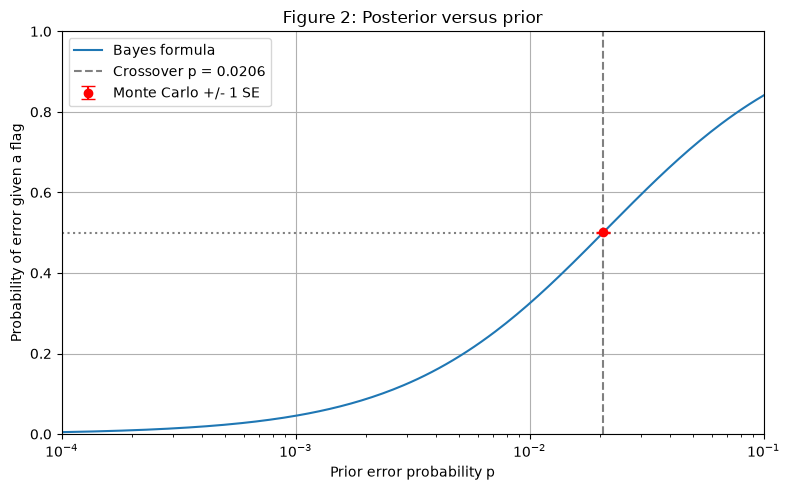

In [13]:
# Make 200 logarithmically spaced prior probabilities
p_plot = np.logspace(-4, -1, 200)
posterior_plot = posterior_error(p_plot)

plt.figure(figsize=(8, 5))

# Exact posterior curve
plt.plot(p_plot, posterior_plot, label="Bayes formula")

# Mark the crossover
plt.axvline(
    p_cross, color="gray", linestyle="--",
    label="Crossover p = 0.0206"
)
plt.axhline(0.5, color="gray", linestyle=":")

# Monte Carlo point with a standard-error bar
plt.errorbar(
    p_cross, posterior_mc, yerr=posterior_se,
    fmt="ro", capsize=5, label="Monte Carlo +/- 1 SE"
)

plt.xscale("log")
plt.xlim(0.0001, 0.1)
plt.ylim(0, 1)
plt.xlabel("Prior error probability p")
plt.ylabel("Probability of error given a flag")
plt.title("Figure 2: Posterior versus prior")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 2 interpretation**

As p increases, a flagged bit is more likely to actually have
an error. The posterior reaches 0.5 at about p = 0.0206.
The Monte Carlo result was 0.500632 with a standard error of
about 0.0008, which is close to the exact value of 0.5.

### 6) Explanation for a manager

The circuit catches 95% of real errors, but it also flags 2%
of correct bits. On a good link, there are many more correct
bits than erroneous bits, so most flags are false alarms.
For p = 0.001, only about 4.54% of flagged bits actually
have errors.

## Step 3: Independence

### 1) Two fair coins

The possible outcomes are HH, HT, TH, and TT.
Each outcome has probability 1/4.

- E1: The first coin is heads.
- E2: The second coin is heads.
- E3: The two coins match.

Each event has probability 1/2.

Each pair happens together only for HH, so:

$$
P(E_1 \cap E_2) = P(E_1 \cap E_3)
= P(E_2 \cap E_3) = \frac14.
$$

The product of the probabilities for each pair is also:

$$
\frac12 \times \frac12 = \frac14.
$$

Therefore, the events are pairwise independent.

However, all three events happen together only for HH:

$$
P(E_1 \cap E_2 \cap E_3) = \frac14.
$$

The product of all three probabilities is:

$$
P(E_1)P(E_2)P(E_3) = \frac18.
$$

Since 1/4 does not equal 1/8, the events are not mutually
independent.

In [14]:
# Random generator for Step 3
rng_step3 = rng.spawn(1)[0]

N_step3 = 1_000_000

# 1 means heads, 0 means tails
coin1 = rng_step3.integers(0, 2, size=N_step3)
coin2 = rng_step3.integers(0, 2, size=N_step3)

# Define the three events
E1 = coin1 == 1
E2 = coin2 == 1
E3 = coin1 == coin2

# Estimate each probability
p1 = E1.mean()
p2 = E2.mean()
p3 = E3.mean()

# Compare products with joint probabilities
print("Events         Product       Joint probability")
print(f"E1 and E2      {p1 * p2:.6f}      {(E1 & E2).mean():.6f}")
print(f"E1 and E3      {p1 * p3:.6f}      {(E1 & E3).mean():.6f}")
print(f"E2 and E3      {p2 * p3:.6f}      {(E2 & E3).mean():.6f}")
print(f"E1, E2, E3     {p1 * p2 * p3:.6f}      {(E1 & E2 & E3).mean():.6f}")

Events         Product       Joint probability
E1 and E2      0.249643      0.250064
E1 and E3      0.250206      0.250064
E2 and E3      0.250279      0.250064
E1, E2, E3     0.125032      0.250064


### 2) Two receivers observing the same bit

The transmitted bit is equally likely to be 0 or 1.
Receiver 1 has an error probability of 0.1, and receiver 2
has an error probability of 0.3.

We compare the receiver outputs for all transmissions,
then separately when the transmitted bit was 0 or 1.

In [15]:
# Simulate one million transmissions
sent_bits = rng_step3.integers(0, 2, size=N_step3)

receiver1 = bsc(sent_bits, p=0.1, rng=rng_step3)
receiver2 = bsc(sent_bits, p=0.3, rng=rng_step3)

# Calculate correlation and an approximate standard error
def corr_with_se(bits1, bits2):
    corr = np.corrcoef(bits1, bits2)[0, 1]

    # Split the samples into 100 groups
    groups1 = np.array_split(bits1, 100)
    groups2 = np.array_split(bits2, 100)

    group_corr = []

    for group1, group2 in zip(groups1, groups2):
        answer = np.corrcoef(group1, group2)[0, 1]
        group_corr.append(answer)

    # Use the variation between groups to estimate the SE
    se = np.std(group_corr, ddof=1) / np.sqrt(100)

    return corr, se

# Select the two groups of transmitted bits
sent0 = sent_bits == 0
sent1 = sent_bits == 1

# Calculate the three correlations
corr_all, se_all = corr_with_se(receiver1, receiver2)

corr0, se0 = corr_with_se(
    receiver1[sent0], receiver2[sent0]
)

corr1, se1 = corr_with_se(
    receiver1[sent1], receiver2[sent1]
)

# Print the results
print("Group          Samples      Correlation     Std. error")
print(f"All bits       {N_step3:7d}      {corr_all:.6f}        {se_all:.6f}")
print(f"Sent bit = 0   {sent0.sum():7d}      {corr0:.6f}        {se0:.6f}")
print(f"Sent bit = 1   {sent1.sum():7d}      {corr1:.6f}        {se1:.6f}")

Group          Samples      Correlation     Std. error
All bits       1000000      0.321180        0.000897
Sent bit = 0    499446      0.002171        0.001433
Sent bit = 1    500554      0.001425        0.001475


**Results**

The overall correlation is about 0.321 because both receivers
observe the same transmitted bit. When we separate the results
by the transmitted bit, the correlations are close to zero
compared with their standard errors. This agrees with the
channels being independent once the transmitted bit is known.

### 3) Effect on a sensor system

When two sensors share a common cause, treating their readings
as independent can count the same information twice and make
the system too confident in its decision.

## Step 4: Bernoulli trials and the Binomial

### 1) Why the error count is Binomial

Each of the 1000 bits either has an error or does not, with
the same error probability p. Assuming the bit errors are
independent, the total number of errors follows a Binomial
distribution with n = 1000.

$$
X \sim \operatorname{Binomial}(1000, p).
$$

In [16]:
from mp1lib import packet_errors
from scipy.stats import binom

# Random generator for Step 4
rng_step4 = rng.spawn(1)[0]

# With p = 0, all three packets should have zero errors
test_counts = packet_errors(
    n_pkt=3, n_bits=4, p=0, rng=test_rng
)

assert np.array_equal(test_counts, np.array([0, 0, 0]))

print("Test error counts:", test_counts)
print("packet_errors test passed.")

Test error counts: [0 0 0]
packet_errors test passed.


### 2) Simulate packet errors and plot the distribution

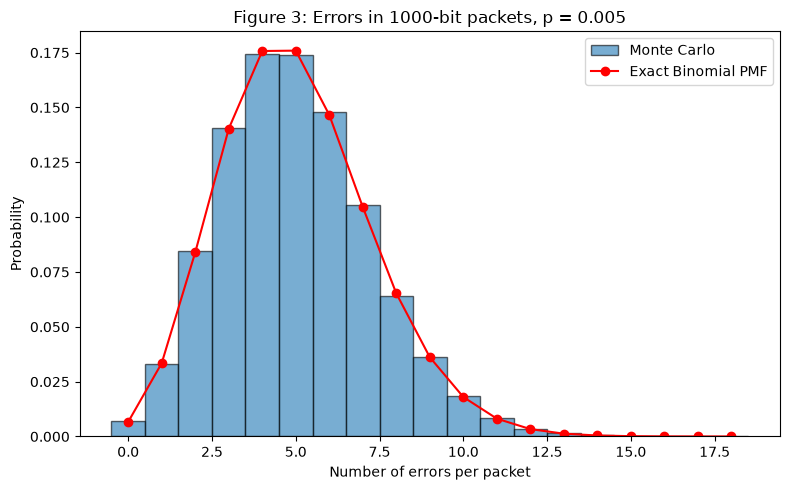

In [17]:
# Simulate 100,000 packets containing 1000 bits each
N_packets = 100_000
n_bits = 1000
p_step4 = 0.005

error_counts = packet_errors(
    N_packets, n_bits, p_step4, rng_step4
)

# Calculate the exact Binomial probabilities
k = np.arange(error_counts.max() + 1)
exact_pmf = binom.pmf(k, n_bits, p_step4)

# Give each integer error count its own histogram bin
bins = np.arange(-0.5, error_counts.max() + 1.5, 1)

plt.figure(figsize=(8, 5))

plt.hist(
    error_counts,
    bins=bins,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Monte Carlo"
)

plt.plot(k, exact_pmf, "ro-", label="Exact Binomial PMF")

plt.xlabel("Number of errors per packet")
plt.ylabel("Probability")
plt.title("Figure 3: Errors in 1000-bit packets, p = 0.005")
plt.legend()
plt.tight_layout()
plt.show()

**Figure 3 interpretation**

The error counts are concentrated around 4–5 errors per
packet. Larger error counts are much less common.

### 3) Compare the mean and variance

For a Binomial distribution, the theoretical mean is:

$$
E[X] = np = 1000(0.005) = 5.
$$

The theoretical variance is:

$$
\operatorname{Var}(X) = np(1-p)
= 1000(0.005)(0.995) = 4.975.
$$

In [18]:
# Calculate the sample mean and sample variance
sample_mean = error_counts.mean()
sample_var = error_counts.var(ddof=1)

# Calculate the theoretical values
exact_mean = n_bits * p_step4
exact_var = n_bits * p_step4 * (1 - p_step4)

# Standard error of the sample mean
mean_se = np.sqrt(exact_var / N_packets)

# Estimate the variance standard error using 100 groups
groups = np.array_split(error_counts, 100)
group_vars = []

for group in groups:
    group_vars.append(group.var(ddof=1))

var_se = np.std(group_vars, ddof=1) / np.sqrt(100)

# Print the comparisons
print("Quantity       Exact         Simulation      Difference      Std. error")
print(f"Mean           {exact_mean:.6f}      {sample_mean:.6f}        {abs(sample_mean - exact_mean):.6f}        {mean_se:.6f}")
print(f"Variance       {exact_var:.6f}      {sample_var:.6f}        {abs(sample_var - exact_var):.6f}        {var_se:.6f}")

Quantity       Exact         Simulation      Difference      Std. error
Mean           5.000000      5.003990        0.003990        0.007053
Variance       4.975000      5.016704        0.041704        0.022467


### 4) Probability of a clean packet

A packet is clean when all 1000 bits have no errors.
Since the bit errors are independent:

$$
P(X = 0) = (1-p)^{1000}.
$$

In [19]:
p_values_step4 = [0.005, 0.001, 0.0001]

print("p        Exact       Monte Carlo    Difference     Std. error")

for p_value in p_values_step4:
    # Simulate packets at this error probability
    counts = packet_errors(
        N_packets, n_bits, p_value, rng_step4
    )

    # Calculate exact and simulated clean probabilities
    exact_clean = (1 - p_value) ** n_bits
    mc_clean = (counts == 0).mean()

    difference = abs(mc_clean - exact_clean)

    clean_se = np.sqrt(
        exact_clean * (1 - exact_clean) / N_packets
    )

    print(
        f"{p_value:<9.4f}"
        f"{exact_clean:<12.6f}"
        f"{mc_clean:<15.6f}"
        f"{difference:<15.6f}"
        f"{clean_se:.6f}"
    )

p        Exact       Monte Carlo    Difference     Std. error
0.0050   0.006654    0.006430       0.000224       0.000257
0.0010   0.367695    0.365660       0.002035       0.001525
0.0001   0.904833    0.905190       0.000357       0.000928


## Step 5: The Poisson Approximation

For a 1000-bit packet, the number of bit errors follows

$$
X \sim \operatorname{Binomial}(n,p),
$$

where

$$
n = 1000.
$$

When $n$ is large and $p$ is small, the Binomial distribution can be approximated by a Poisson distribution with

$$
\lambda = np.
$$

Therefore, we compare

$$
X \sim \operatorname{Binomial}(1000,p)
$$

with

$$
Y \sim \operatorname{Poisson}(1000p).
$$

The total variation distance between the two probability mass functions is

$$
d_{TV} = \frac{1}{2}\sum_k |P_X(k)-P_Y(k)|.
$$

In [20]:
import numpy as np

In [21]:
# Test tv_distance()

from mp1lib import tv_distance

same1 = np.array([0.2, 0.3, 0.5])
same2 = np.array([0.2, 0.3, 0.5])

disjoint1 = np.array([1.0, 0.0])
disjoint2 = np.array([0.0, 1.0])

print("Identical PMFs:", tv_distance(same1, same2))
print("Disjoint PMFs:", tv_distance(disjoint1, disjoint2))

Identical PMFs: 0.0
Disjoint PMFs: 1.0


In [22]:
from scipy.stats import binom, poisson
from mp1lib import tv_distance

# Step 5 parameters
n = 1000
p_values = [0.5, 0.05, 0.005, 0.001, 0.0005]

tv_results = []

print("p          lambda       Total variation    Poisson tail")
print("-------------------------------------------------------")

for p in p_values:
    lam = n * p

    k_max = int(max(
        binom.ppf(1 - 1e-12, n, p),
        poisson.ppf(1 - 1e-12, lam)
    ))

    poisson_tail = 1 - poisson.cdf(k_max, lam)

    k = np.arange(0, k_max + 1)

    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)

    binom_pmf = np.append(binom_pmf, 1 - binom_pmf.sum())
    poisson_pmf = np.append(poisson_pmf, 1 - poisson_pmf.sum())

    d_tv = tv_distance(binom_pmf, poisson_pmf)
    tv_results.append(d_tv)

    print(
        f"{p:<10g} {lam:<12g} "
        f"{d_tv:<18.6f} {poisson_tail:.2e}"
    )

p          lambda       Total variation    Poisson tail
-------------------------------------------------------
0.5        500          0.166057           9.08e-13
0.05       50           0.012446           8.24e-13
0.005      5            0.001228           9.93e-13
0.001      1            0.000276           3.00e-13
0.0005     0.5          0.000114           3.22e-13


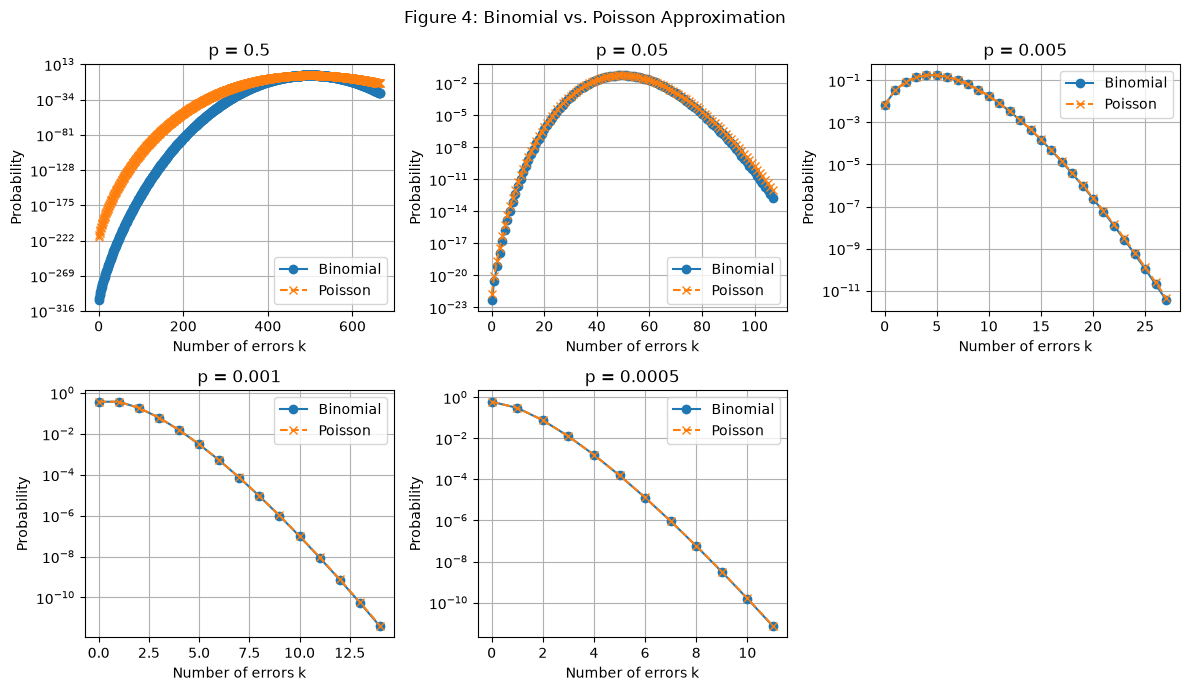

In [23]:
import numpy as np
import matplotlib.pyplot as plt
# Figure 4: Binomial vs. Poisson PMFs

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for i, p in enumerate(p_values):
    lam = n * p

    k_max = int(max(
        binom.ppf(1 - 1e-12, n, p),
        poisson.ppf(1 - 1e-12, lam)
    ))

    k_plot = np.arange(0, k_max + 1)

    binom_pmf = binom.pmf(k_plot, n, p)
    poisson_pmf = poisson.pmf(k_plot, lam)

    axes[i].plot(k_plot, binom_pmf, "o-", label="Binomial")
    axes[i].plot(k_plot, poisson_pmf, "x--", label="Poisson")

    axes[i].set_title(f"p = {p}")
    axes[i].set_xlabel("Number of errors k")
    axes[i].set_ylabel("Probability")
    axes[i].set_yscale("log")
    axes[i].legend()
    axes[i].grid(True)

# Leave the sixth subplot blank
axes[5].axis("off")

fig.suptitle("Figure 4: Binomial vs. Poisson Approximation")
plt.tight_layout()
plt.show()

**Figure 4 interpretation**

The Poisson approximation improves as $p$ becomes smaller. At $p=0.5$, the Binomial and Poisson distributions are noticeably different. As $p$ decreases, the two distributions become almost indistinguishable. This agrees with the total variation distances, which decrease from 0.166057 at $p=0.5$ to 0.000114 at $p=0.0005$.

In [24]:
# Function to calculate total variation distance for any p
def binomial_poisson_tv(p, n=1000):
    lam = n * p

    k_max = int(max(
        binom.ppf(1 - 1e-12, n, p),
        poisson.ppf(1 - 1e-12, lam)
    ))

    k = np.arange(0, k_max + 1)

    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)

    binom_pmf = np.append(binom_pmf, 1 - binom_pmf.sum())
    poisson_pmf = np.append(poisson_pmf, 1 - poisson_pmf.sum())

    return tv_distance(binom_pmf, poisson_pmf)

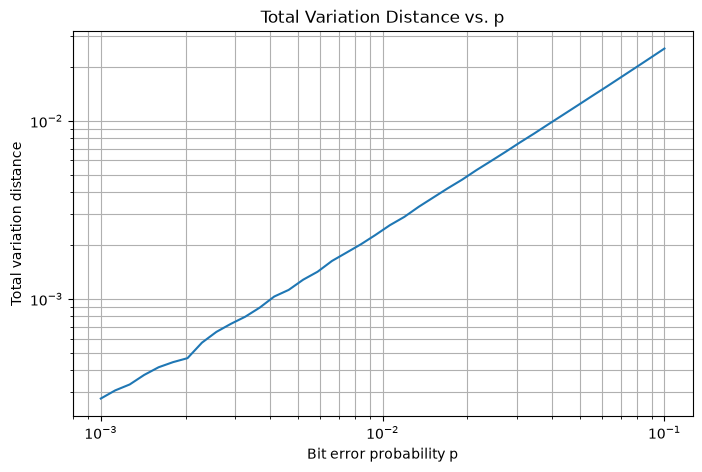

In [25]:
# Check that total variation increases with p

p_check = np.logspace(-3, -1, 40)

tv_check = np.array([
    binomial_poisson_tv(p) for p in p_check
])

plt.figure(figsize=(8, 5))
plt.loglog(p_check, tv_check)

plt.xlabel("Bit error probability p")
plt.ylabel("Total variation distance")
plt.title("Total Variation Distance vs. p")
plt.grid(True, which="both")

plt.show()

In [26]:
# Bisection search for d_TV = 0.01
low = 0.001
high = 0.1
target = 0.01

for _ in range(50):
    mid = (low + high) / 2

    if binomial_poisson_tv(mid) < target:
        low = mid
    else:
        high = mid

p_threshold = (low + high) / 2

# Le Cam bound: n*p^2 = 0.01
p_lecam = np.sqrt(0.01 / n)

print(f"Bisection threshold p = {p_threshold:.6f}")
print(f"To 2 significant figures: p = {p_threshold:.2g}")
print(f"TV distance at threshold = {binomial_poisson_tv(p_threshold):.6f}")
print(f"Le Cam threshold p = {p_lecam:.6f}")

Bisection threshold p = 0.040394
To 2 significant figures: p = 0.04
TV distance at threshold = 0.010000
Le Cam threshold p = 0.003162


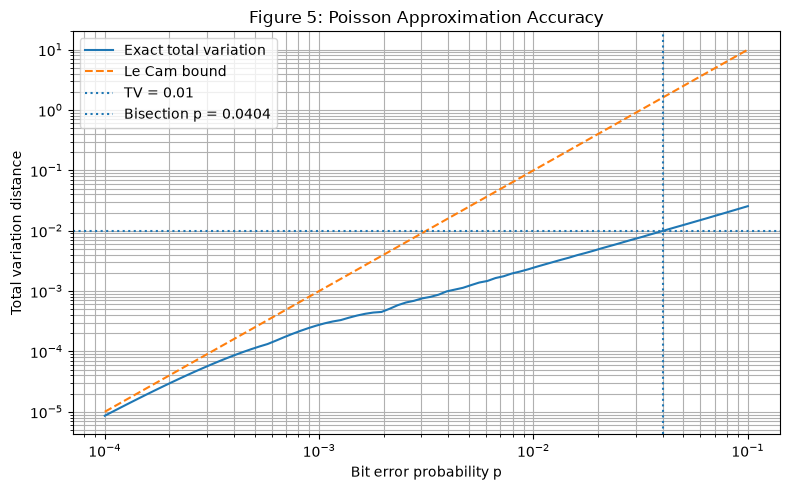

In [27]:
# Figure 5: Total variation distance vs. p

p_curve = np.logspace(-4, -1, 80)

tv_curve = np.array([
    binomial_poisson_tv(p)
    for p in p_curve
])

# Le Cam bound
lecam_curve = n * p_curve**2

plt.figure(figsize=(8, 5))

plt.loglog(p_curve, tv_curve, label="Exact total variation")
plt.loglog(p_curve, lecam_curve, "--", label="Le Cam bound")

plt.axhline(0.01, linestyle=":", label="TV = 0.01")
plt.axvline(
    p_threshold,
    linestyle=":",
    label=f"Bisection p = {p_threshold:.4f}"
)

plt.xlabel("Bit error probability p")
plt.ylabel("Total variation distance")
plt.title("Figure 5: Poisson Approximation Accuracy")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

**Figure 5 interpretation**

The total variation distance decreases as $p$ becomes smaller, so the Poisson approximation becomes more accurate for rare bit errors. The bisection search gives a threshold of

$$
p \approx 0.0404,
$$

or $p=0.040$ to two significant figures, for $d_{TV}=0.01$. The Le Cam bound gives the more conservative value

$$
p \approx 0.0032.
$$

Therefore, the actual total variation criterion allows a value of $p$ about one order of magnitude larger than the Le Cam bound predicts. The Le Cam bound is useful as a simple guarantee, but it is conservative.

### When is the Poisson approximation trustworthy?

The Poisson approximation is most trustworthy when the number of trials $n$ is large and the error probability $p$ is small. In this regime, the Binomial distribution has many trials with rare events, and the Poisson parameter $\lambda=np$ remains manageable.

## Step 6: Retransmissions and the Geometric Distribution

Let $T$ be the number of transmission attempts needed until the first clean packet is received.

The number of attempts until the first clean packet is geometric because each transmission is an independent trial with the same probability $q$ of success. The assumption that transmission outcomes are independent from one attempt to the next makes the geometric model valid.

Therefore,

$$
T \sim \operatorname{Geometric}(q).
$$

We use the convention that $T$ counts the **number of attempts**, so its support starts at 1:

$$
T=1,2,3,\ldots
$$

This is different from the convention that counts the number of failures before the first success, which starts at 0.

The probability mass function is

$$
P(T=k)=(1-q)^{k-1}q,
\qquad k=1,2,3,\ldots
$$

The theoretical mean is

$$
E[T]=\frac{1}{q},
$$

and the theoretical variance is

$$
\operatorname{Var}(T)=\frac{1-q}{q^2}.
$$

For this step,

$$
q=0.7.
$$

Therefore,

$$
E[T]=\frac{1}{0.7}=1.4286
$$

and

$$
\operatorname{Var}(T)
=
\frac{1-0.7}{(0.7)^2}
=
\frac{0.3}{0.49}
=
0.6122.
$$

In [28]:
from mp1lib import attempts_until_clean

# Random generator for Step 6
rng_step6 = rng.spawn(1)[0]

# Step 6 parameters
q_step6 = 0.7
N_step6 = 100_000

# Simulate number of attempts until first clean packet
attempts = attempts_until_clean(
    N_step6, q_step6, rng_step6
)

# Theoretical values
mean_theory = 1 / q_step6
var_theory = (1 - q_step6) / q_step6**2

# Simulation values
mean_sim = attempts.mean()
var_sim = attempts.var(ddof=1)

# Differences
mean_diff = abs(mean_sim - mean_theory)
var_diff = abs(var_sim - var_theory)

# Standard error of the sample mean
mean_se = np.sqrt(var_theory / N_step6)

print("Quantity     Theory       Simulation     Difference")
print("---------------------------------------------------")
print(
    f"Mean         {mean_theory:.6f}     "
    f"{mean_sim:.6f}       {mean_diff:.6f}"
)
print(
    f"Variance     {var_theory:.6f}     "
    f"{var_sim:.6f}       {var_diff:.6f}"
)
print()
print(f"Standard error of mean = {mean_se:.6f}")

Quantity     Theory       Simulation     Difference
---------------------------------------------------
Mean         1.428571     1.426640       0.001931
Variance     0.612245     0.603924       0.008321

Standard error of mean = 0.002474


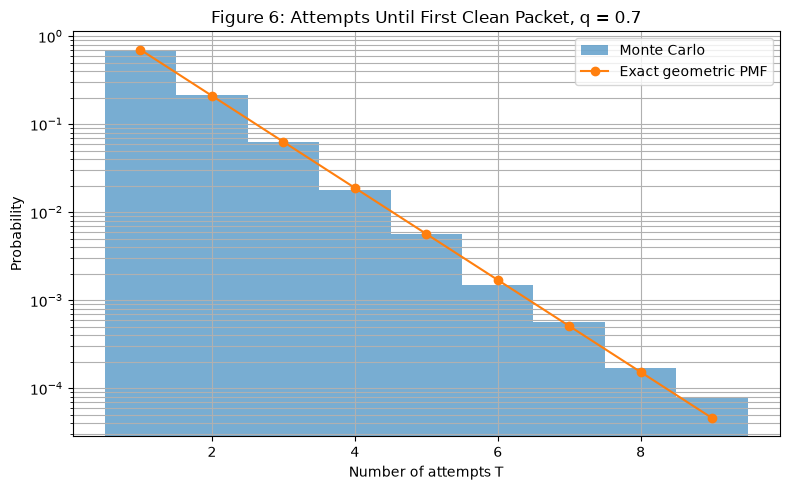

In [29]:
# Figure 6: Geometric distribution

k_geo = np.arange(1, attempts.max() + 1)

# Exact geometric PMF
exact_geo_pmf = q_step6 * (1 - q_step6) ** (k_geo - 1)

plt.figure(figsize=(8, 5))

# Monte Carlo histogram as a density
plt.hist(
    attempts,
    bins=np.arange(0.5, attempts.max() + 1.5, 1),
    density=True,
    alpha=0.6,
    label="Monte Carlo"
)

# Exact geometric PMF
plt.plot(
    k_geo,
    exact_geo_pmf,
    "o-",
    label="Exact geometric PMF"
)

plt.yscale("log")
plt.xlabel("Number of attempts T")
plt.ylabel("Probability")
plt.title("Figure 6: Attempts Until First Clean Packet, q = 0.7")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

**Figure 6 interpretation**

The Monte Carlo histogram closely follows the exact geometric PMF. The probability decreases rapidly as the number of attempts increases, showing that most packets succeed within the first few attempts. The simulated mean of 1.433190 is close to the theoretical mean of 1.428571, with a difference of 0.004619. The simulated variance of 0.619163 is close to the theoretical variance of 0.612245, with a difference of 0.006918.

The geometric model is memoryless, so after five failed attempts the probability of success on the sixth attempt is still $q=0.7$. This result depends on the assumption that transmission attempts are independent and have the same success probability. On a real radio link, channel conditions such as fading or interference can persist between attempts, causing correlated errors and making the memoryless assumption less realistic.

In [30]:
# Verify the memoryless property of the geometric distribution

pairs = [(1, 2), (3, 2), (5, 2)]

print("m   n   Simulation    Theory       Difference     Std. error")
print("-------------------------------------------------------------")

for m, n_value in pairs:

    # Condition on T > m
    survived_m = attempts > m
    N_conditioned = survived_m.sum()

    # Estimate P(T > m+n | T > m)
    simulated = (
        attempts[survived_m] > (m + n_value)
    ).mean()

    # Theoretical P(T > n)
    theoretical = (1 - q_step6) ** n_value

    difference = abs(simulated - theoretical)

    se = np.sqrt(
        theoretical * (1 - theoretical) / N_conditioned
    )

    print(
        f"{m:<3d} {n_value:<3d} "
        f"{simulated:<13.6f} "
        f"{theoretical:<12.6f} "
        f"{difference:<14.6f} "
        f"{se:.6f}"
    )

m   n   Simulation    Theory       Difference     Std. error
-------------------------------------------------------------
1   2   0.085925      0.090000     0.004075       0.001651
3   2   0.089818      0.090000     0.000182       0.005631
5   2   0.107759      0.090000     0.017759       0.018789


### Memorylessness conclusion

For all three cases, the simulated conditional probabilities are close to the theoretical value

$$
P(T>n)=(1-q)^n=(0.3)^2=0.09.
$$

The differences are within the sampling uncertainty indicated by the standard errors. This supports the memoryless property of the geometric distribution:

$$
P(T>m+n\mid T>m)=P(T>n).
$$

In a retransmission system, this means that after several failed attempts, the probability of needing additional attempts does not depend on how many failures have already occurred.